In [ ]:

import pandas as pd
import numpy as np
import pylab as plt
import pypsa

from pathlib import Path

years = [2025, 2030, 2040, 2050]

out_dir = Path("results/final_results")



In [9]:
tech_colors = {

    'CCGT': '#D98242',
    'Biomass plant': '#71A45B',
    'Nuclear plant': '#9670BA',
    'Solar PV': '#E8BC38',
    'Wind turbine - onshore': '#42A9AD',
    'Wind turbine - offshore': '#2474B5',
    'BEV': '#36A6A1',
    'ICE car': '#A67C60',
    'Residential Appliance': '#B0B5BC',
    'Battery': '#6C68BC',
    'CCGT CCS': '#A95332',
    'Biomass plant CCS': '#35794A',
    'Residential gas boiler': '#C17B42',
    'Residential heat pump': '#B17FB1',
    'Industrial machinery - fossil': '#B18060',
    'Industrial machinery - fossil CCS': '#825C50',
    'Industrial machinery - electricity': '#5188C3',
    'Industrial HTP - fossil': '#A65F50',
    'Industrial HTP - fossil CCS': '#71566C',
    'BEV - existing': '#36A6A1',
    'ICE car - existing': '#A67C60',
    'CCGT - existing': '#D98242',
    'Residential gas boiler - existing': '#C17B42',
    'Industrial machinery - fossil - existing': '#B18060',
    'Industrial HTP - fossil - existing': '#A65F50',
    'SMR': '#858585',
    'SMR with CCS': '#3478B9',
    'Electrolysis': '#16A085',
    'SMR - existing': "#8585858D",
    'SMR with CCS - existing': "#3479B99D",
    'Electrolysis - existing': "#16A08489"
}




In [10]:
def get_tech_color(name):

    # handle MultiIndex tuples as well as ordinary strings
    names = name if isinstance(name, tuple) else [name]

    for item in names:
        tech = str(item).strip()

        # check exact name first
        if tech in tech_colors:
            return tech_colors[tech]

        # remove investment vintage, e.g. CCGT_2030 -> CCGT
        if tech.rsplit('_', 1)[-1].isdigit():
            tech = tech.rsplit('_', 1)[0]

        if tech in tech_colors:
            return tech_colors[tech]

    # default colour for anything not in the dictionary
    return '#BDBDBD'

def get_tech_color(name):
    """Resolve a technology or a tuple of labels to a consistent colour."""
    names = name if isinstance(name, tuple) else [name]
    for item in names:
        tech = str(item).strip()
        if tech in tech_colors:
            return tech_colors[tech]
        # CCGT_2030 -> CCGT, SMR - existing_2025 -> SMR - existing
        if tech.rsplit('_', 1)[-1].isdigit():
            tech = tech.rsplit('_', 1)[0]
        if tech in tech_colors:
            return tech_colors[tech]
    return '#BDBDBD'


def plot_main_ebs(scen):
    """Hydrogen energy balance for one scenario."""
    fig, ax = plt.subplots(figsize=(10, 4))
    df = scen.statistics.energy_balance(bus_carrier='Hydrogen')
    df = df.set_index(df.index.get_level_values(1)).T
    df.plot(kind='bar', stacked=True, rot=0,
            color=[get_tech_color(c) for c in df.columns], ax=ax)
    ax.set_ylabel('MWh')
    ax.set_title(scen.name)
    fig.tight_layout()
    plt.show()


def plot_main_ebs_complete(scen):
    """Five end-use energy balances side-by-side."""
    fig, ax = plt.subplots(1, 5, figsize=(20, 4))
    carriers = ['Residential electricity', 'Residential heat',
                'Transportation', 'Industrial machinery', 'Industrial HTP']
    for n, c in enumerate(carriers):
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar', stacked=True, rot=0,
                color=[get_tech_color(tech) for tech in df.columns], ax=ax[n])
        ax[n].set_ylabel('Mvkm' if c == 'Transportation' else 'MWh')
        ax[n].set_title(c)
    fig.tight_layout()
    plt.show()


def plot_elc_emi(scen):
    """Electricity and CO2 energy balances.

    Last two panels preserve the original energy-balance cumsum calculation.
    For genuine cumulative emissions, use the CO2 Store stock instead.
    """
    fig, ax = plt.subplots(1, 5, figsize=(20, 4))
    for n, c in enumerate(['Electricity', 'CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar', stacked=True, rot=0, color=[get_tech_color(tech) for tech in df.columns], ax=ax[n])
        ax[n].set_ylabel('tCO2' if 'CO2' in c else 'MWh')
        ax[n].set_title(c)
        ax[n].legend(bbox_to_anchor=(1, -0.5))

    # Existing diagnostic calculation preserved for minimal changes.
    for n, c in enumerate(['CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c).cumsum(axis=1)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar', stacked=True, rot=0, color=[get_tech_color(tech) for tech in df.columns], ax=ax[n + 3])
        ax[n + 3].set_ylabel('tCO2')
        ax[n + 3].set_title(f'Cumulative {c} (diagnostic)')
        ax[n + 3].legend(bbox_to_anchor=(1, -0.5))
    fig.tight_layout()
    plt.show()


def plot_electrolysis_heatmaps(results):
    """2025 / 2050 electrolysis share as a function of scenario inputs."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, year in zip(axes, [2025, 2050]):
        data = results[results['Year'] == year].pivot(index='Gas multiplier', columns='CAPEX multiplier', values='Electrolysis share (%)').reindex(index=[1, 3, 5.5, 8], columns=[1, 0.75, 0.5, 0.25])
        im = ax.imshow(data.values, vmin=0, vmax=100, cmap='YlGnBu', aspect='auto')
        ax.set_xticks(range(4))
        ax.set_xticklabels(['0%', '25%', '50%', '75%'])
        ax.set_yticks(range(4))
        ax.set_yticklabels(['1x', '3x', '5.5x', '8x'])
        ax.set_xlabel('Electrolyser CAPEX reduction')
        ax.set_ylabel('Natural gas price multiplier')
        ax.set_title(f'Electrolysis share in {year}')
        for i in range(4):
            for j in range(4):
                value = data.iloc[i, j]
                if value == value:  # skip NaN
                    ax.text(j, i, f'{value:.0f}%', ha='center', va='center', color='white' if value > 50 else 'black')
    fig.colorbar(im, ax=axes, label='Share of hydrogen production (%)', shrink=0.8)
    plt.show()


def plot_cost_emissions(results):
    """Discounted system objective against cumulative CO2 in 2050."""
    data = results[results['Year'] == 2050]
    fig, ax = plt.subplots(figsize=(9, 6))
    for gas, group in data.groupby('Gas multiplier'):
        ax.scatter(group['Cumulative CO2 (Mt)'], group['System objective (trillion €)'], label=f'Gas price {gas}x', s=80)
    ax.set_title('System costs and cumulative emissions')
    ax.set_xlabel('Cumulative CO2 by 2050 (MtCO2)')
    ax.set_ylabel('Discounted model objective (trillion €)')
    ax.legend(title='Gas-price assumption')
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


def plot_carbon_sensitivity(carbon_results):
    """CO2-price sensitivity: hydrogen production route and cumulative CO2."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    colors = [get_tech_color('SMR'), get_tech_color('SMR with CCS'), get_tech_color('Electrolysis')]

    carbon_results[['Grey', 'Blue', 'Electrolysis']].plot(ax=axes[0], marker='o', color=colors)
    axes[0].set_title('2050 hydrogen mix versus carbon price')
    axes[0].set_xlabel('Carbon price (€/tCO2)')
    axes[0].set_ylabel('Hydrogen production share (%)')
    axes[0].grid(alpha=0.3)

    carbon_results[['Grey', 'Blue', 'Electrolysis']].plot(ax=axes[1], marker='o', color=colors, legend=False)
    axes[1].set_xlim(100, 110)
    axes[1].set_ylim(-5, 105)
    axes[1].set_title('Tipping point: €104–105/tCO2')
    axes[1].set_xlabel('Carbon price (€/tCO2)')
    axes[1].set_ylabel('Hydrogen production share (%)')
    axes[1].grid(alpha=0.3)

    carbon_results['Cumulative CO2'].plot(ax=axes[2], marker='o')
    axes[2].set_title('Cumulative emissions versus carbon price')
    axes[2].set_xlabel('Carbon price (€/tCO2)')
    axes[2].set_ylabel('Cumulative emissions (MtCO2)')
    axes[2].grid(alpha=0.3)

    fig.tight_layout()
    plt.show()

In [16]:
# load saved models

networks = {f.stem: pypsa.Network(f) for f in sorted(out_dir.glob("gas_x*_elec_x*.nc"))}

print(f"Loaded {len(networks)} gas/CAPEX scenarios")

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x0.25' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x0.5' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x0.75' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x1' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x3_elec_x0.25' has buses, carriers, generators, link

Loaded 16 gas/CAPEX scenarios


In [17]:
results = []


for name, n in networks.items():

    # only analyse gasprice/electrolyser CAPEX scenarios here
    if not name.startswith('gas_x'):
        continue


    # every link producing hydrogen
    h2_links = n.links.index[n.links.bus1 == 'Hydrogen']

    # h2 production is the -link output p1 so x snapshot hours = energy MWh
    production = (
        -n.links_t.p1[h2_links]
    ).mul(n.snapshot_weightings.generators, axis=0)

    # sum production in each model year
    production = production.groupby(level=0).sum().T

    # combine existing and new production techs
    production['route'] = (
        n.links.loc[production.index, 'carrier']
        .str.replace(' - existing', '', regex=False)
    )

    production = production.groupby('route').sum().T / 1e6

    # get gas price and electrolyser CAPEX multipliers
    parts = name.split('_')
    gas = float(parts[1].replace('x', ''))
    capex = float(parts[3].replace('x', ''))

    for y in years:

        grey = production.at[y, 'SMR']
        blue = production.at[y, 'SMR with CCS']
        electrolysis = production.at[y, 'Electrolysis']

        total = grey + blue + electrolysis

        results.append({
            'Scenario': name,
            'Year': y,
            'Gas multiplier': gas,
            'CAPEX multiplier': capex,
            'Grey': grey,
            'Blue': blue,
            'Electrolysis': electrolysis,
            'Electrolysis share (%)': 100 * electrolysis / total,
            'Cumulative CO2 (Mt)': (
                n.stores_t.e['CO2 atmosphere']
                .loc[y].iloc[-1] / 1e6
            ),
            'System objective (trillion €)': n.objective / 1e12
        })

results = pd.DataFrame(results)

display(results.round(2))

display(results[results.Year == 2025])
print(results.groupby('Gas multiplier')['Electrolysis share (%)'].max())




,Scenario,Year,Gas multiplier,CAPEX multiplier,Grey,Blue,Electrolysis,Electrolysis share (%),Cumulative CO2 (Mt),System objective (trillion €)
0,gas_x1_elec_x0.25,2025,1.0,0.25,23.21,1.38,0.00,0.00,80.15,2.51
1,gas_x1_elec_x0.25,2030,1.0,0.25,25.12,0.00,-0.00,-0.00,147.15,2.51
2,gas_x1_elec_x0.25,2040,1.0,0.25,26.02,0.00,0.00,0.00,209.35,2.51
3,gas_x1_elec_x0.25,2050,1.0,0.25,26.78,0.00,0.00,0.00,251.08,2.51
4,gas_x1_elec_x0.5,2025,1.0,0.50,23.21,1.38,0.00,0.00,80.15,2.51
...,...,...,...,...,...,...,...,...,...,...
59,gas_x8_elec_x0.75,2050,8.0,0.75,4.16,0.00,22.62,84.47,129.39,3.99
60,gas_x8_elec_x1,2025,8.0,1.00,24.59,0.00,0.00,0.01,59.44,3.99
61,gas_x8_elec_x1,2030,8.0,1.00,6.55,-0.00,18.57,73.94,88.29,3.99
62,gas_x8_elec_x1,2040,8.0,1.00,5.42,0.00,20.59,79.15,110.38,3.99


,Scenario,Year,Gas multiplier,CAPEX multiplier,Grey,Blue,Electrolysis,Electrolysis share (%),Cumulative CO2 (Mt),System objective (trillion €)
0,gas_x1_elec_x0.25,2025,1.0,0.25,23.209253,1.38408,0.000000,0.000000,80.150811,2.509008
4,gas_x1_elec_x0.5,2025,1.0,0.50,23.209253,1.38408,0.000000,0.000000,80.150811,2.509008
8,gas_x1_elec_x0.75,2025,1.0,0.75,23.209253,1.38408,0.000000,0.000000,80.150811,2.509008
12,gas_x1_elec_x1,2025,1.0,1.00,23.209253,1.38408,0.000000,0.000000,80.150811,2.509008
16,gas_x3_elec_x0.25,2025,3.0,0.25,15.507593,0.00000,9.085740,36.943914,70.333274,3.076055
20,gas_x3_elec_x0.5,2025,3.0,0.50,20.545936,0.00000,4.047398,16.457296,71.280160,3.078945
24,gas_x3_elec_x0.75,2025,3.0,0.75,24.563018,0.00000,0.030315,0.123265,71.881494,3.080558
28,gas_x3_elec_x1,2025,3.0,1.00,24.563018,0.00000,0.030315,0.123265,71.881494,3.081597
32,gas_x5.5_elec_x0.25,2025,5.5,0.25,14.794150,0.00000,9.799183,39.844877,61.757500,3.557855
36,gas_x5.5_elec_x0.5,2025,5.5,0.50,18.462003,0.00000,6.131330,24.930862,61.447977,3.561602


Gas multiplier
1.0     0.000000
3.0    57.916078
5.5    78.088735
8.0    84.474417
Name: Electrolysis share (%), dtype: float64


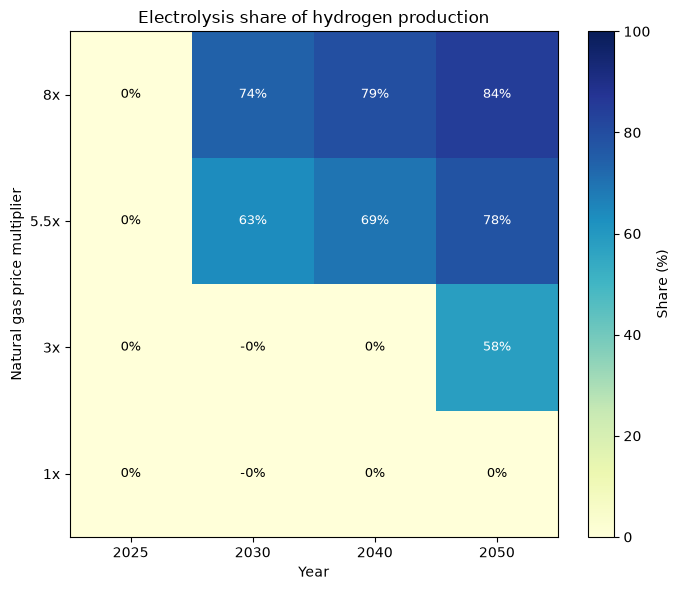

In [18]:
capex_sel = 1.0
df = results[results['CAPEX multiplier'] == capex_sel]

share = df.pivot_table(
    index='Gas multiplier',
    columns='Year',
    values='Electrolysis share (%)',
).sort_index(ascending=False)          # highest gas price on top

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(share.values, cmap='YlGnBu', vmin=0, vmax=100, aspect='auto')

# Axis labels
ax.set_xticks(range(len(share.columns)))
ax.set_xticklabels(share.columns)
ax.set_yticks(range(len(share.index)))
ax.set_yticklabels([f'{round(g, 2):g}x' for g in share.index])
ax.set_xlabel('Year')
ax.set_ylabel('Natural gas price multiplier')
ax.set_title('Electrolysis share of hydrogen production')

# Write the value in each cell
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        val = share.iloc[i, j]
        ax.text(
            j, i, f'{val:.0f}%',
            ha='center', va='center',
            color='white' if val > 50 else 'black',
            fontsize=9,
        )

fig.colorbar(im, ax=ax, label='Share (%)')
plt.tight_layout()
plt.show()

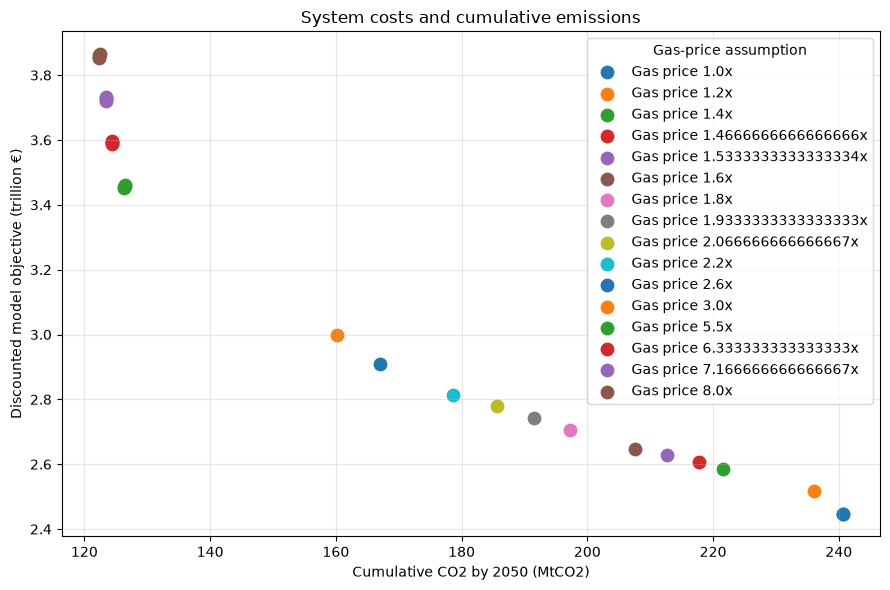

In [7]:
# plot_electrolysis_heatmaps(results)

plot_cost_emissions(results)


^
### Heatmap
Interaction between natural gas prices and electrolyser investment costs in determining the share of electrolysis in total hydrogen production. The 2025 and 2050 panels shows differences between early adoption and long-term technology choice.

### Dot plot
Relationship between cumulative atmospheric emissions and modelled discounted system costs under the gas price and electrolyser CAPEX scenarios. Each point corresponds to an optimised scenario.

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'carbon_price_0' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'carbon_price_100' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'carbon_price_101' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'carbon_price_102' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'carbon_price_103' has buses, carriers, generators, links, 

[{'CO2 price': 0, 'Grey': np.float64(100.0), 'Blue': np.float64(0.0), 'Electrolysis': np.float64(0.0), 'Cumulative CO2': np.float64(269.7606829388199)}, {'CO2 price': 100, 'Grey': np.float64(100.0), 'Blue': np.float64(0.0), 'Electrolysis': np.float64(0.0), 'Cumulative CO2': np.float64(249.26140029160308)}, {'CO2 price': 101, 'Grey': np.float64(100.0), 'Blue': np.float64(0.0), 'Electrolysis': np.float64(0.0), 'Cumulative CO2': np.float64(249.13922375778102)}, {'CO2 price': 102, 'Grey': np.float64(100.0), 'Blue': np.float64(0.0), 'Electrolysis': np.float64(0.0), 'Cumulative CO2': np.float64(248.91010091865795)}, {'CO2 price': 103, 'Grey': np.float64(100.0), 'Blue': np.float64(0.0), 'Electrolysis': np.float64(0.0), 'Cumulative CO2': np.float64(248.70589581611952)}, {'CO2 price': 104, 'Grey': np.float64(100.0), 'Blue': np.float64(0.0), 'Electrolysis': np.float64(0.0), 'Cumulative CO2': np.float64(248.63119601185267)}, {'CO2 price': 105, 'Grey': np.float64(-1.7491441867117718e-30), 'Blue': 

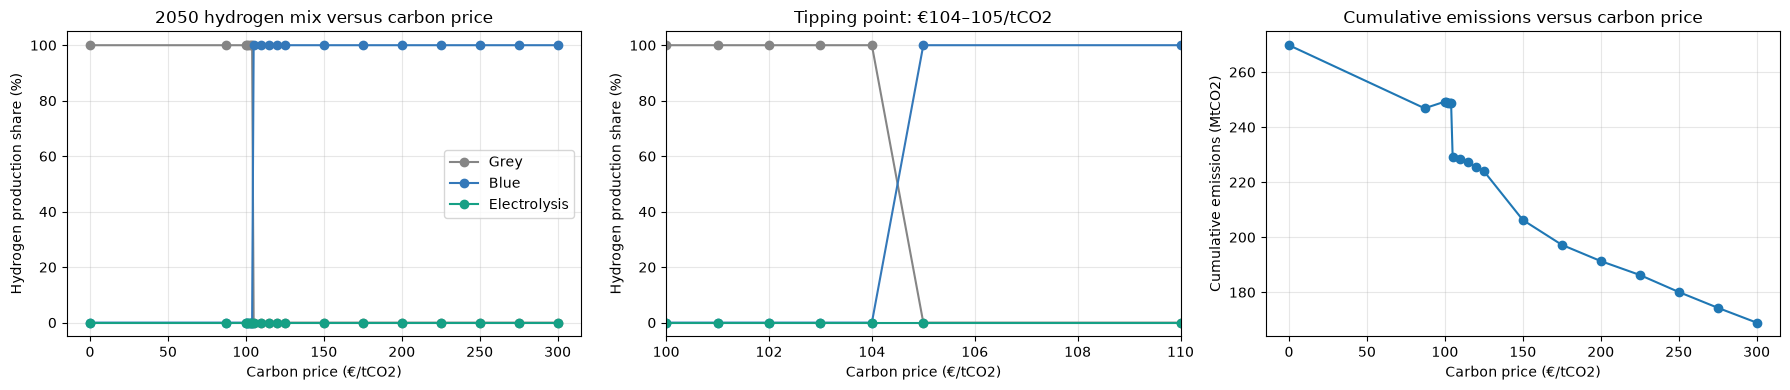

,Grey,Blue,Electrolysis,Cumulative CO2
CO2 price,,,,
100,1.000000e+02,0.0,0.0,249.261400
101,1.000000e+02,0.0,0.0,249.139224
102,1.000000e+02,0.0,0.0,248.910101
103,1.000000e+02,0.0,0.0,248.705896
104,1.000000e+02,0.0,0.0,248.631196
105,-1.749144e-30,100.0,0.0,229.087240
110,0.000000e+00,100.0,0.0,228.417339


In [16]:
carbon_results = []

for file in sorted(Path('results/carbon_runs').glob('carbon_price_*.nc')):

    price = int(file.stem.split('_')[-1])
    n = pypsa.Network(file)

    h2_links = n.links.index[n.links.bus1 == 'Hydrogen']

    # hydrogen production during 2050
    production = (-n.links_t.p1.loc[2050, h2_links]).mul(n.snapshot_weightings.generators.loc[2050], axis=0).sum() / 1e6

    # include existing plants in their production categories
    production.index = (n.links.loc[production.index, 'carrier'].str.replace(' - existing', '', regex=False).values)

    production = production.groupby(level=0).sum()
    total = production.sum()

    carbon_results.append({
        'CO2 price': price,
        'Grey': 100 * production.get('SMR', 0) / total,
        'Blue': 100 * production.get('SMR with CCS', 0) / total,
        'Electrolysis': 100 * production.get('Electrolysis', 0) / total,
        'Cumulative CO2': (
            n.stores_t.e['CO2 atmosphere'].loc[2050].iloc[-1] / 1e6
        )
    })
print(carbon_results)
carbon_results = (pd.DataFrame(carbon_results).set_index('CO2 price').sort_index())


plot_carbon_sensitivity(carbon_results)

display(carbon_results.loc[100:110])



^ Carbon price sensitivity of hydrogen production pathways and cumulative atmospheric emissions. The switch from grey SMR to SMR with CCS between approximately €104 and €105/tCO2 shows a technology-selection threshold under the model's assumed costs and constraints.